### Margin decline analysis

We observe the following pattern in our data: the profit margin is declining while the business is growing.

In this notebook, we will break down this trend to identify what has changed: prices, costs, discounts, or sales mix.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

In [37]:
input_file = "../data/dear_neighbour.xlsx"

sheets = pd.read_excel(input_file, sheet_name=None)
sheet_names = sheets.keys()

sheet_names

dict_keys(['fact_sales', 'dim_products', 'dim_stores', 'dim_customers', 'dim_suppliers'])

In [38]:
sales = sheets['fact_sales']
products = sheets['dim_products']

[As we saw](https://github.com/TAbramovskaya/dear-neighbour/blob/main/python/data_overview.ipynb), selling prices remained relatively stable over the two-year period.

Therefore, we will overlook the fact that we have a single purchase price for each product across both years.

In [39]:
sales['year'] = sales['datetime'].dt.year

sales = (
    sales.merge(
        products[['product_id', 'category', 'subcategory', 'purchase_price_rub']],
        on='product_id',
        how='left'
    )
)

sales['unit_revenue'] = sales['line_total'] / sales['quantity']

sales['cost'] = sales['purchase_price_rub'] * sales['quantity']

sales['gross_profit'] = sales['line_total'] - sales['cost']

In [40]:
sales.sample()

,receipt_id,datetime,store_id,product_id,customer_id,quantity,unit_price,discount_percent,line_total,payment_method,year,category,subcategory,purchase_price_rub,unit_revenue,cost,gross_profit
68621,1019305,2025-09-14 17:41:00,8,32,NaN,1,314.02,0,314.02,card,2025,meat and poultry,chicken,253.24,314.02,253.24,60.78


#### Compare overall and category-level margins by year

In [41]:
summary_by_year = (
    sales
    .groupby(['year'])
    .agg(
        revenue=('line_total', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        costs=('cost', 'sum'),
        quantity=('quantity', 'sum'),
        receipts=('receipt_id', 'nunique'),
    )
)

In [42]:
summary_by_year['gross_margin'] = summary_by_year['gross_profit'] / summary_by_year['revenue']

summary_by_year['avg_receipt'] = summary_by_year['revenue'] / summary_by_year['receipts']

In [43]:
summary_by_year

,revenue,gross_profit,costs,quantity,receipts,gross_margin,avg_receipt
year,,,,,,,
2024,10432017.93,2751014.93,7681003.00,50334,11019,0.263709,946.730005
2025,11457582.40,3008785.06,8448797.34,55196,11771,0.262602,973.373749


In [44]:
summary_by_category = (
    sales
    .groupby(['year', 'category'])
    .agg(
        revenue=('line_total', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        costs=('cost', 'sum'),
        quantity=('quantity', 'sum'),
        receipts=('receipt_id', 'nunique')
    )
)

In [45]:
summary_by_category['gross_margin'] = summary_by_category['gross_profit'] / summary_by_category['revenue']

summary_by_category['revenue_share'] = (
        summary_by_category['revenue']
        / summary_by_category.groupby(level=['year'])['revenue'].transform('sum')
)

In [46]:
summary_by_category.sample(2)

,,revenue,gross_profit,costs,quantity,receipts,gross_margin,revenue_share
year,category,,,,,,,
2025,snacks,587133.70,182952.35,404181.35,3956,2688,0.311603,0.051244
2024,bread and baked goods,194230.17,55887.71,138342.46,3290,2236,0.287740,0.018619


#### Margin Decomposition: Mix Effect vs. Within-Category Effect

Overall gross margin is a weighted average of category-level gross margins:

$$ M_t = \sum_c s^t_c m^t_c$$

where:
- $M_t$ — overall gross margin in year $t$.
- $s^t_c$ — category $c$'s share of total revenue in year $t$.
- $m^t_c$ — category $c$'s gross margin in year $t$.

Therefore, overall gross margin depends on two factors: *how total revenue is distributed across categories* and *how profitable each category is*.

Let $t = 1$ denote 2024, and $t = 2$ denote 2025. The total change in gross margin between two years is:

$$\Delta M = M_2 - M_1 = \sum_c s^2_c m^2_c - \sum_c s^1_c m^1_c$$

We want to separate this change into two effects:

- **Mix effect:** the impact of changes in category revenue shares.
- **Within-category margin effect:** the impact of changes in category-level margins.

Both category revenue shares and category margins may change simultaneously. To separate their effects, we use a symmetric decomposition:

$$\Delta M_{\text{mix}} = \sum_c (s^2_c-s^1_c) \frac{m^1_c+m^2_c}{2}$$

$$\Delta M_{\text{margin}} = \sum_c (m^2_c-m^1_c) \frac{s^1_c+s^2_c}{2}$$

The two effects add up exactly to the observed change in overall gross margin:

$$\Delta M = \Delta M_{\text{mix}} + \Delta M_{\text{margin}}$$

In [47]:
summary_by_category = summary_by_category.reset_index()

In [48]:
shares = summary_by_category.pivot(
    index='category',
    columns='year',
    values='revenue_share'
)

shares.sample(2)

year,2024,2025
category,,
diary,0.042292,0.040219
snacks,0.052853,0.051244


In [49]:
margins = summary_by_category.pivot(
    index='category',
    columns='year',
    values='gross_margin'
)

margins.sample(2)

year,2024,2025
category,,
sweets,0.319743,0.318382
snacks,0.311485,0.311603


In [50]:
t1 = 2024
t2 = 2025

comparison = pd.DataFrame(index=shares.index)

comparison['mix_effect_pp'] = (100 * (shares[t2] - shares[t1]) * (margins[t1] + margins[t2]) / 2)

comparison['margin_effect_pp'] = (100 * (margins[t2] - margins[t1]) * (shares[t1] + shares[t2]) / 2)

comparison['total_effect_pp'] = (comparison['mix_effect_pp'] + comparison['margin_effect_pp'])

comparison.sort_values('total_effect_pp')

,mix_effect_pp,margin_effect_pp,total_effect_pp
category,,,
alcohol,-0.187028,-0.025909,-0.212937
ready-to-eat meals,-0.067913,-0.002101,-0.070014
diary,-0.056750,-0.004530,-0.061279
snacks,-0.050111,0.000609,-0.049502
pantry staples,-0.045259,0.001934,-0.043325
sweets,-0.017632,-0.006929,-0.024561
meat and poultry,-0.008857,-0.014328,-0.023185
baby food,0.006893,-0.001979,0.004914
bread and baked goods,0.024425,0.000824,0.025249


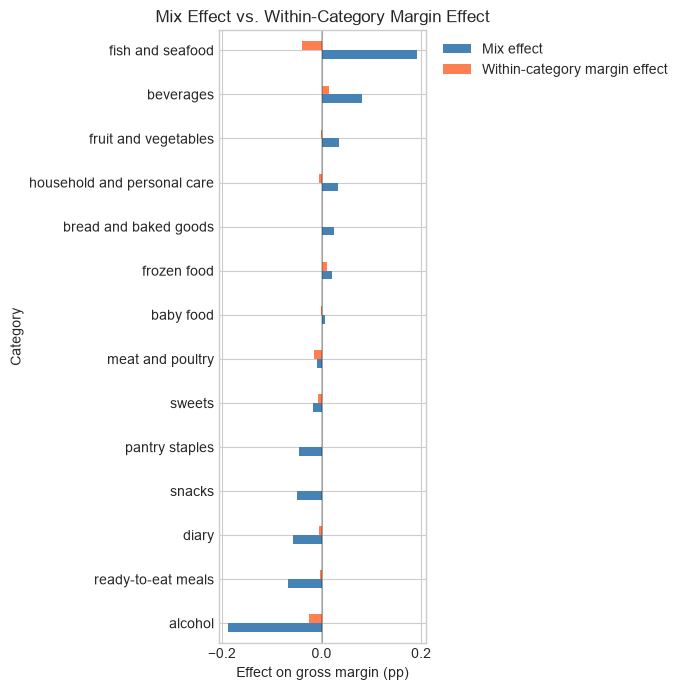

In [51]:
plot_data = comparison[['mix_effect_pp', 'margin_effect_pp']].sort_values('mix_effect_pp')

ax = plot_data.plot(kind='barh', figsize=(7, 7), width=0.4, color={'mix_effect_pp': 'steelblue', 'margin_effect_pp': 'coral'})

ax.axvline(0, color='black', linewidth=0.3)
ax.set_xlabel('Effect on gross margin (pp)')
ax.set_ylabel('Category')
ax.set_title('Mix Effect vs. Within-Category Margin Effect')

handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    ['Mix effect', 'Within-category margin effect'],
    loc='upper left',
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

**The mix effect has a greater absolute impact on gross margin than the within-category margin effect in most categories.**

- `Meat and poultry` is the only exception, where the within-category margin effect is stronger than the mix effect.
- Some categories show opposing effects: in `non-food products` the positive mix effect is partially offset by a small negative within-category margin effect.
- `Fish and seafood` has the largest positive mix effect, although it is partially offset by a decline in the category's gross margin.

Overall, changes in sales mix appear to be the dominant factor influencing gross margin across most categories.